# Mobilidade Urbana e Sazonalidade no Citi Bike NYC (2024)
**Estudo de Caso em Visualização de Dados (ECVD — UFPB)**

---

## 1. Escopo, Desafio e Rigor de Modelagem
Este caderno implementa o pipeline completo de **Pré-processamento, Modelagem Analítica e Engenharia Visual** comparando dois regimes climáticos contrastantes do sistema **Citi Bike (Nova York)**:
- **Inverno rigoroso (`Janeiro/2024`)**: baixas temperaturas, menor fluxo turístico e ocorrência de tempestade de inverno (06–07/Jan).
- **Fim de verão (`Setembro/2024`)**: temperaturas amenas, intenso uso recreativo/turístico e máxima pressão operacional sobre as estações.

### Diretrizes de Boas Práticas Aplicadas (Tufte, Wilke, Cleveland & McGill, Berinato)
1. **Integridade Estatística e Limpeza Estrita**:
   - Remoção de *spillover* mensal (viagens iniciadas em `31/Dez/2023` ou `31/Ago/2024` que terminaram após a meia-noite), garantindo contagem exata de dias por mês.
   - Filtragem de ruídos operacionais (`1 min ≤ duração ≤ 1.440 min`) e barreira geográfica contra *Null Island* (`40,4°N–41,0°N`; `74,3°W–73,7°W`).
   - **Normalização diária obrigatória** nas curvas horárias (`viagens / nº de dias do regime`), eliminando o viés de escala (*Lie Factor*) causado pela proporção desigual entre dias úteis e fins de semana.
2. **Maximização da Razão Tinta-Dados ($\text{RTD} = \frac{d-t}{T}$)**:
   - Estilo explícito orientado a objetos (`fig, ax = plt.subplots`), fundo limpo, remoção de `spines` supérfluas, gradeado sutil restrito ao eixo quantitativo e **rotulagem direta (*direct labeling*)** em substituição a caixas de legenda isoladas.
3. **Arquitetura Cromática Sem Colisão Semântica (Acessível a Daltônicos)**:
   - **Sazonalidade**: Azul Aço (`#2B5C8F`, Inverno/Jan) vs. Âmbar Quente (`#D95F02`, Fim de Verão/Set).
   - **Frota Tecnológica**: Verde-Petróleo Focal (`#00796B`, Bicicleta Elétrica) vs. Cinza Neutro de Contexto (`#CBD5E1`, Bicicleta Clássica).
   - **Perfil de Usuário**: Azul Marinho (`#1D4E89`, Membro Anual) vs. Terracota (`#C85A32`, Usuário Casual).
   - **Saldo Espacial**: Escala divergente discretizada (`RdBu`, 6 faixas simétricas em torno de zero).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import seaborn as sns

# ── 1. Configuração Tipográfica e Estética Global (Alta RTD) ─────────────────
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans', 'Arial'],
    'font.size': 10.5,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5,
    'axes.labelcolor': '#1E293B',
    'xtick.color': '#334155',
    'ytick.color': '#334155',
    'axes.edgecolor': '#CBD5E1',
    'axes.linewidth': 0.8,
    'savefig.dpi': 300,
    'savefig.facecolor': 'white',
})

# Paletas semânticas independentes (evita interferência cognitiva entre RVs)
COR_JAN = '#2B5C8F'       # Inverno (Janeiro/2024)
COR_SET = '#D95F02'       # Fim de Verão (Setembro/2024)
COR_ELETRICA = '#00796B'  # Destaque tecnológico: Bicicleta Elétrica
COR_CLASSICA = '#CBD5E1'  # Contexto neutro: Bicicleta Clássica
COR_MEMBRO = '#1D4E89'    # Membro Anual (recorrente/pendular)
COR_CASUAL = '#C85A32'    # Usuário Casual (lazer/turismo)

DIR_PLOTS = Path('plots')
DIR_PLOTS.mkdir(parents=True, exist_ok=True)

def fmt_int(valor: float | int) -> str:
    """Formata número inteiro com separador de milhar brasileiro (ponto)."""
    return f"{int(round(valor)):,}".replace(',', '.')

def fmt_milhoes(valor: float, casas: int = 2) -> str:
    """Formata grandezas na casa dos milhões com vírgula decimal brasileira."""
    return f"{valor / 1e6:.{casas}f}M".replace('.', ',')

def localizar_pasta_dados(codigo_mes: str) -> Path:
    """Resolve de forma portável o diretório contendo os CSVs brutos do mês."""
    nome_pasta = f"{codigo_mes}-citibike-tripdata"
    for base in [Path('.'), Path('..'), Path('../..'), Path('../../..')]:
        candidato = (base / nome_pasta).resolve()
        if candidato.exists() and any(candidato.glob('*.csv')):
            return candidato
    raise FileNotFoundError(f"Pasta '{nome_pasta}' não encontrada.")

# ── 2. Função de ETL Rigoroso ────────────────────────────────────────────────
FERIADOS_2024 = {
    pd.Timestamp('2024-01-01').date(),  # New Year's Day
    pd.Timestamp('2024-01-15').date(),  # Martin Luther King Jr. Day
    pd.Timestamp('2024-09-02').date(),  # Labor Day
}

def carregar_mes_limpo(codigo_mes: str, inicio_mes: str, fim_mes: str, rotulo_mes: str) -> pd.DataFrame:
    pasta = localizar_pasta_dados(codigo_mes)
    arquivos = sorted(pasta.glob('*.csv'))
    colunas = [
        'rideable_type', 'started_at', 'ended_at',
        'start_station_name', 'end_station_name',
        'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual'
    ]
    df = pd.concat([pd.read_csv(f, usecols=colunas, low_memory=False) for f in arquivos], ignore_index=True)
    n_bruto = len(df)

    df['started_at'] = pd.to_datetime(df['started_at'])
    df['ended_at'] = pd.to_datetime(df['ended_at'])
    df['duracao_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60.0

    # Filtro estrito do mês calendário + duração física válida (1 min a 24h) + coordenadas em NYC
    mascara = (
        (df['started_at'] >= pd.Timestamp(inicio_mes))
        & (df['started_at'] < pd.Timestamp(fim_mes))
        & (df['duracao_min'] >= 1.0)
        & (df['duracao_min'] <= 1440.0)
        & df['start_lat'].between(40.4, 41.0)
        & df['start_lng'].between(-74.3, -73.7)
        & df['end_lat'].between(40.4, 41.0)
        & df['end_lng'].between(-74.3, -73.7)
    )
    df = df.loc[mascara].copy()

    # Tradução semântica para Português Brasileiro
    df['perfil'] = df['member_casual'].map({'member': 'Membro Anual', 'casual': 'Usuário Casual'})
    df['frota'] = df['rideable_type'].map({'electric_bike': 'Bicicleta Elétrica', 'classic_bike': 'Bicicleta Clássica'})
    df['data'] = df['started_at'].dt.date
    df['hora'] = df['started_at'].dt.hour
    eh_fds_ou_feriado = (df['started_at'].dt.day_of_week >= 5) | (df['data'].isin(FERIADOS_2024))
    df['regime_dia'] = np.where(eh_fds_ou_feriado, 'Fim de Semana / Feriado', 'Dia Útil')
    df['mes'] = rotulo_mes

    retencao = len(df) / n_bruto * 100
    print(f"[{rotulo_mes}] Bruto: {fmt_int(n_bruto)} -> Válido no mês: {fmt_int(len(df))} ({retencao:.2f}%)")
    return df

df_jan = carregar_mes_limpo('202401', '2024-01-01', '2024-02-01', 'Janeiro/2024')
df_set = carregar_mes_limpo('202409', '2024-09-01', '2024-10-01', 'Setembro/2024')

[Janeiro/2024] Bruto: 1.888.085 -> Válido no mês: 1.881.587 (99.66%)
[Setembro/2024] Bruto: 4.997.898 -> Válido no mês: 4.980.371 (99.65%)


---
## 2. RV 1 — Impacto Sazonal no Volume e no Mix de Usuários
**Escolhas de Engenharia Visual:**
- **Barras horizontais agrupadas (`orient='h'`) com marco zero estrito (*zero baseline*)**: eliminam textos rotacionados a 90° e codificam magnitude pelo canal de maior precisão perceptual (comprimento alinhado 2D).
- **Barra horizontal 100% empilhada complementar**: evidencia a transformação estrutural na composição relativa do sistema sem usar gráficos de setores (*pie charts*).

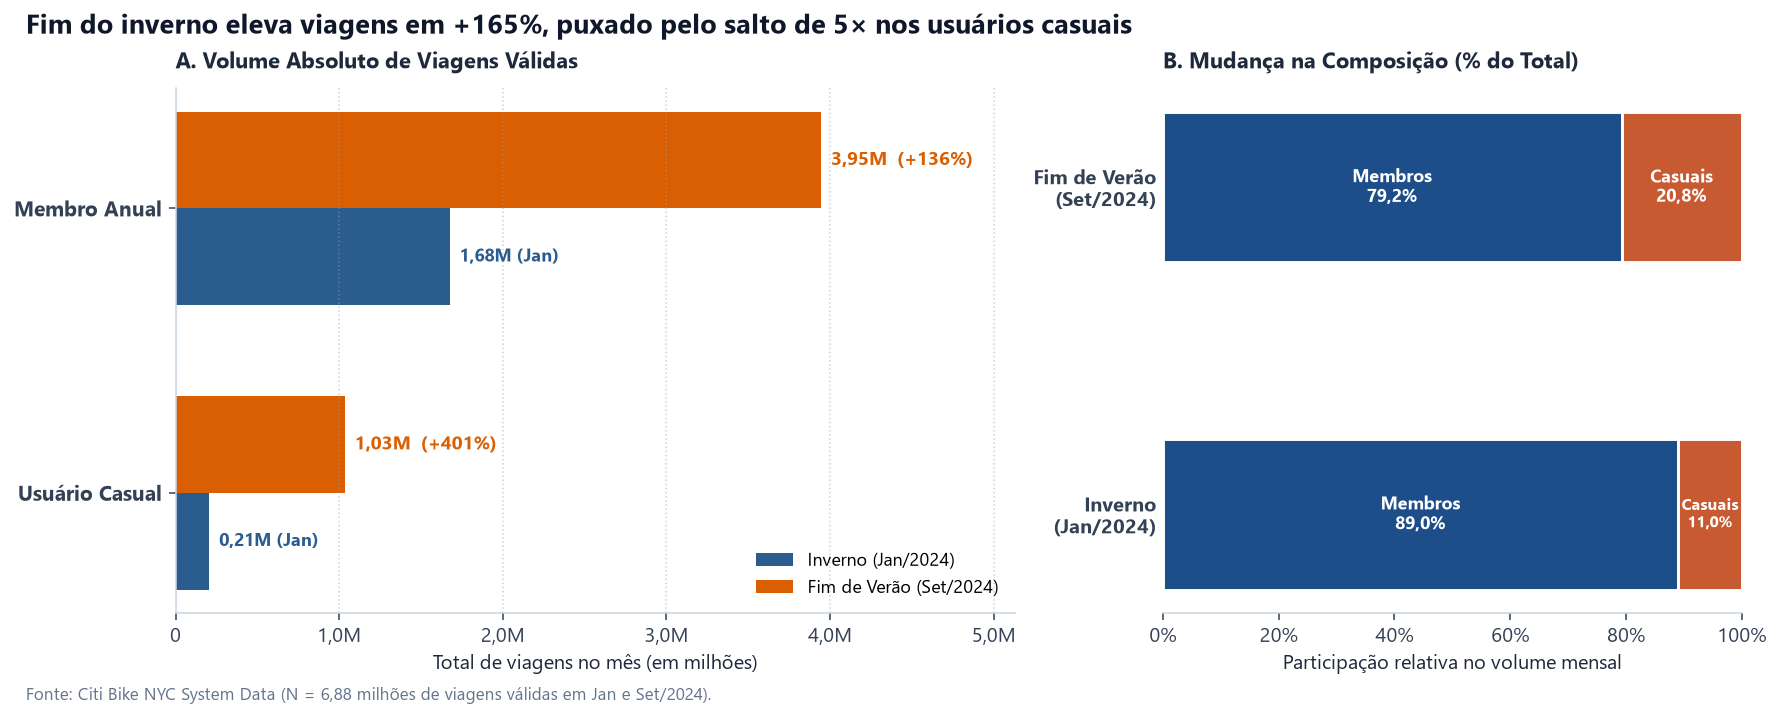

In [2]:
perfis_ordem = ['Usuário Casual', 'Membro Anual']  # Membro Anual no topo (maior magnitude)
cnt_jan = df_jan['perfil'].value_counts().reindex(perfis_ordem)
cnt_set = df_set['perfil'].value_counts().reindex(perfis_ordem)

crescimento_total = (len(df_set) - len(df_jan)) / len(df_jan) * 100

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12.6, 4.8), gridspec_kw={'width_ratios': [1.45, 1.0]}, constrained_layout=True
)

fig.suptitle(
    f"Fim do inverno eleva viagens em +{crescimento_total:.0f}%, puxado pelo salto de 5× nos usuários casuais",
    fontsize=14, fontweight='bold', color='#0F172A', x=0.01, ha='left'
)

# ── Painel A: Magnitude Absoluta (Barras Horizontais Pareadas) ──────────────
y = np.arange(len(perfis_ordem))
altura_b = 0.34

ax1.barh(y - altura_b / 2, cnt_jan.values, height=altura_b, color=COR_JAN, label='Inverno (Jan/2024)')
ax1.barh(y + altura_b / 2, cnt_set.values, height=altura_b, color=COR_SET, label='Fim de Verão (Set/2024)')

ax1.set_title('A. Volume Absoluto de Viagens Válidas', loc='left', fontsize=11.5, pad=10, color='#1E293B')
ax1.set_yticks(y)
ax1.set_yticklabels(perfis_ordem, fontsize=11, fontweight='bold')
ax1.set_xlim(0, cnt_set.max() * 1.30)
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: fmt_milhoes(v, 1) if v > 0 else '0'))
ax1.set_xlabel('Total de viagens no mês (em milhões)')
ax1.grid(axis='x', ls=':', alpha=0.45, color='#94A3B8')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

for idx_p in range(len(perfis_ordem)):
    v_j = cnt_jan.values[idx_p]
    v_s = cnt_set.values[idx_p]
    alta_pct = (v_s - v_j) / v_j * 100
    ax1.text(v_j + 60_000, y[idx_p] - altura_b / 2, f"{fmt_milhoes(v_j)} (Jan)",
             va='center', ha='left', fontsize=9.5, color=COR_JAN, fontweight='bold')
    ax1.text(v_s + 60_000, y[idx_p] + altura_b / 2,
             f"{fmt_milhoes(v_s)}  (+{alta_pct:.0f}%)",
             va='center', ha='left', fontsize=9.8, color=COR_SET, fontweight='bold')

ax1.legend(loc='lower right', frameon=False, fontsize=9.5)

# ── Painel B: Participação Relativa (Barra 100% Empilhada) ──────────────────
meses_rot = ['Inverno\n(Jan/2024)', 'Fim de Verão\n(Set/2024)']
pct_membro = np.array([cnt_jan['Membro Anual'] / cnt_jan.sum() * 100, cnt_set['Membro Anual'] / cnt_set.sum() * 100])
pct_casual = 100.0 - pct_membro
y_m = np.arange(2)

ax2.barh(y_m, pct_membro, height=0.46, color=COR_MEMBRO, edgecolor='white', linewidth=1.5)
ax2.barh(y_m, pct_casual, left=pct_membro, height=0.46, color=COR_CASUAL, edgecolor='white', linewidth=1.5)

ax2.set_title('B. Mudança na Composição (% do Total)', loc='left', fontsize=11.5, pad=10, color='#1E293B')
ax2.set_yticks(y_m)
ax2.set_yticklabels(meses_rot, fontsize=10.5, fontweight='bold')
ax2.set_xlim(0, 100)
ax2.xaxis.set_major_formatter(ticker.PercentFormatter())
ax2.set_xlabel('Participação relativa no volume mensal')
ax2.tick_params(axis='y', length=0)

for i in range(2):
    ax2.text(pct_membro[i] / 2, y_m[i], f"Membros\n{pct_membro[i]:.1f}%".replace('.', ','),
             va='center', ha='center', color='white', fontweight='bold', fontsize=9.5)
    tam_cas = 8.3 if pct_casual[i] < 13 else 9.2
    ax2.text(pct_membro[i] + pct_casual[i] / 2, y_m[i], f"Casuais\n{pct_casual[i]:.1f}%".replace('.', ','),
             va='center', ha='center', color='white', fontweight='bold', fontsize=tam_cas)

sns.despine(ax=ax2, top=True, right=True, left=True, trim=True)

fig.text(0.01, -0.03, 'Fonte: Citi Bike NYC System Data (N = 6,88 milhões de viagens válidas em Jan e Set/2024).',
         fontsize=8.5, color='#64748B')

plt.savefig(DIR_PLOTS / 'rv1_sazonalidade_perfil.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 3. RV 2 — Preferência Tecnológica da Frota (Elétrica vs. Clássica)
**Refatoração Estrutural (Correção de Antipadrão):**
- O gráfico original empilhava contagens absolutas na vertical, impedindo comparar proporções entre grupos de tamanhos distintos (`Casual` vs. `Membro`) e deixando o segmento superior sem linha de base zero comum.
- Aplicamos **Barras Horizontais 100% Empilhadas Ordenadas** ancorando a **Bicicleta Elétrica** (cor focal `#00796B`) na origem `x = 0%` e mantendo a **Bicicleta Clássica** em cinza neutro de contexto (`#CBD5E1`), acompanhadas do volume absoluto à direita.

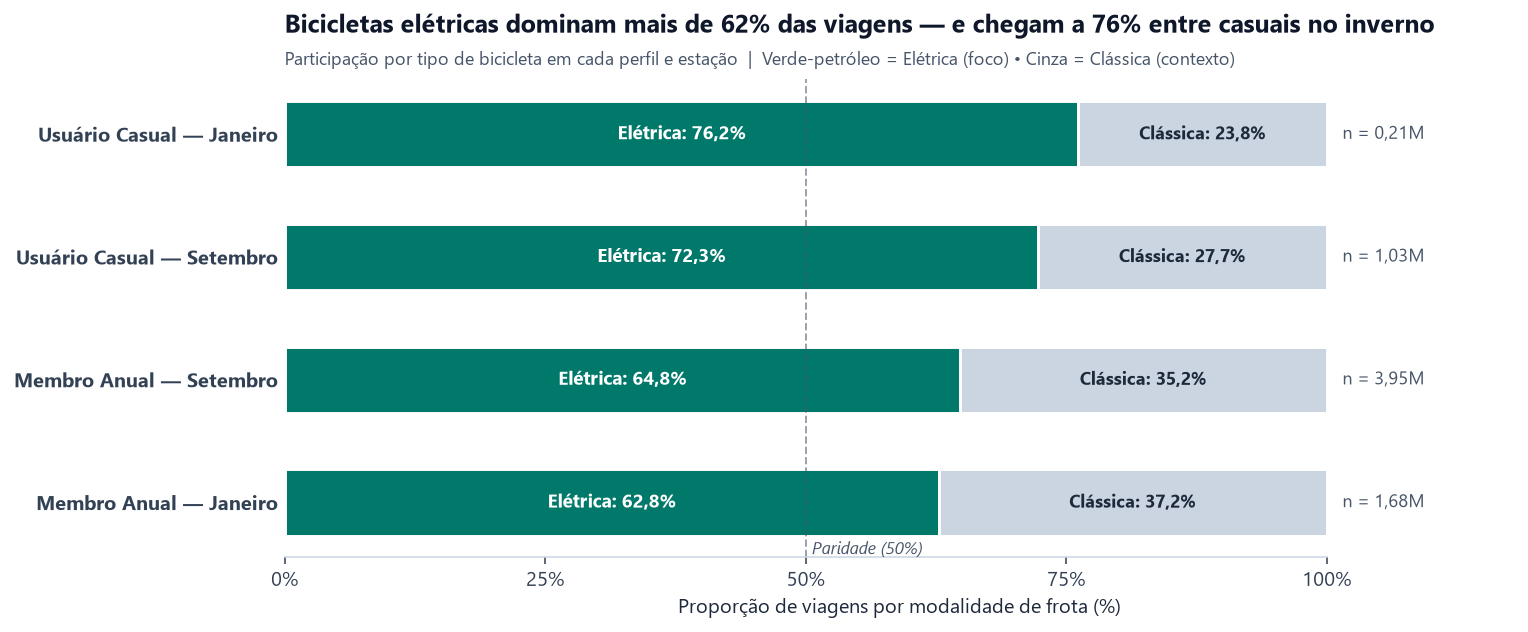

In [3]:
df_todos = pd.concat([df_jan, df_set], ignore_index=True)
df_todos['coorte'] = df_todos['perfil'] + ' — ' + df_todos['mes'].str.replace('/2024', '')

tab_abs = pd.crosstab(df_todos['coorte'], df_todos['frota'])
tab_pct = tab_abs.div(tab_abs.sum(axis=1), axis=0) * 100.0
tab_pct['total'] = tab_abs.sum(axis=1)
tab_pct = tab_pct.sort_values('Bicicleta Elétrica', ascending=True)  # Maior preferência no topo

fig, ax = plt.subplots(figsize=(10.8, 4.4), constrained_layout=True)

y_c = np.arange(len(tab_pct))
el_vals = tab_pct['Bicicleta Elétrica'].values
cl_vals = tab_pct['Bicicleta Clássica'].values

ax.barh(y_c, el_vals, height=0.54, color=COR_ELETRICA, edgecolor='white', linewidth=1.5)
ax.barh(y_c, cl_vals, left=el_vals, height=0.54, color=COR_CLASSICA, edgecolor='white', linewidth=1.5)

ax.set_title(
    'Bicicletas elétricas dominam mais de 62% das viagens — e chegam a 76% entre casuais no inverno',
    loc='left', fontsize=13, fontweight='bold', color='#0F172A', pad=24
)
ax.text(
    0, 1.03,
    'Participação por tipo de bicicleta em cada perfil e estação  |  Verde-petróleo = Elétrica (foco) • Cinza = Clássica (contexto)',
    transform=ax.transAxes, fontsize=9.5, color='#475569'
)

ax.set_yticks(y_c)
ax.set_yticklabels(tab_pct.index, fontsize=10.5, fontweight='bold')
ax.set_xlim(0, 118)  # Espaço à direita para anotar N absoluto sem poluir as barras
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(ticker.PercentFormatter())
ax.set_xlabel('Proporção de viagens por modalidade de frota (%)')
ax.axvline(50, color='#475569', ls='--', lw=1.0, alpha=0.55)
ax.text(50.6, -0.42, 'Paridade (50%)', fontsize=8.5, color='#475569', style='italic')

sns.despine(ax=ax, top=True, right=True, left=True, trim=True)
ax.tick_params(axis='y', length=0)

for i, (_, linha) in enumerate(tab_pct.iterrows()):
    p_el = linha['Bicicleta Elétrica']
    p_cl = linha['Bicicleta Clássica']
    tot = linha['total']
    ax.text(p_el / 2, y_c[i], f"Elétrica: {p_el:.1f}%".replace('.', ','),
            va='center', ha='center', color='white', fontweight='bold', fontsize=9.8)
    ax.text(p_el + p_cl / 2, y_c[i], f"Clássica: {p_cl:.1f}%".replace('.', ','),
            va='center', ha='center', color='#1E293B', fontweight='bold', fontsize=9.3)
    ax.text(101.5, y_c[i], f"n = {fmt_milhoes(tot)}",
            va='center', ha='left', color='#475569', fontsize=9.2)

plt.savefig(DIR_PLOTS / 'rv2_preferencia_frota.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 4. RV 3 — Ritmo Circadiano: Demanda Horária Média Diária
**Correção de Modelagem e Boas Práticas em Séries Temporais (`Aula 14`):**
- **Correção de escala**: dividimos o volume de cada hora pelo número exato de dias daquele regime no mês (`21 dias úteis`, `10 dias não úteis/feriados` em Jan e `9` em Set), obtendo a **Média de Viagens por Hora por Dia**.
- **Pequenos múltiplos coordenados (`sharey=True`)**: separam claramente a assinatura **bimodal pendular** dos dias úteis (picos às 08h e 17h) da curva **unimodal recreativa** dos fins de semana/feriados, usando faixas de referência e rótulos diretos sem marcadores pontuais poluídos.

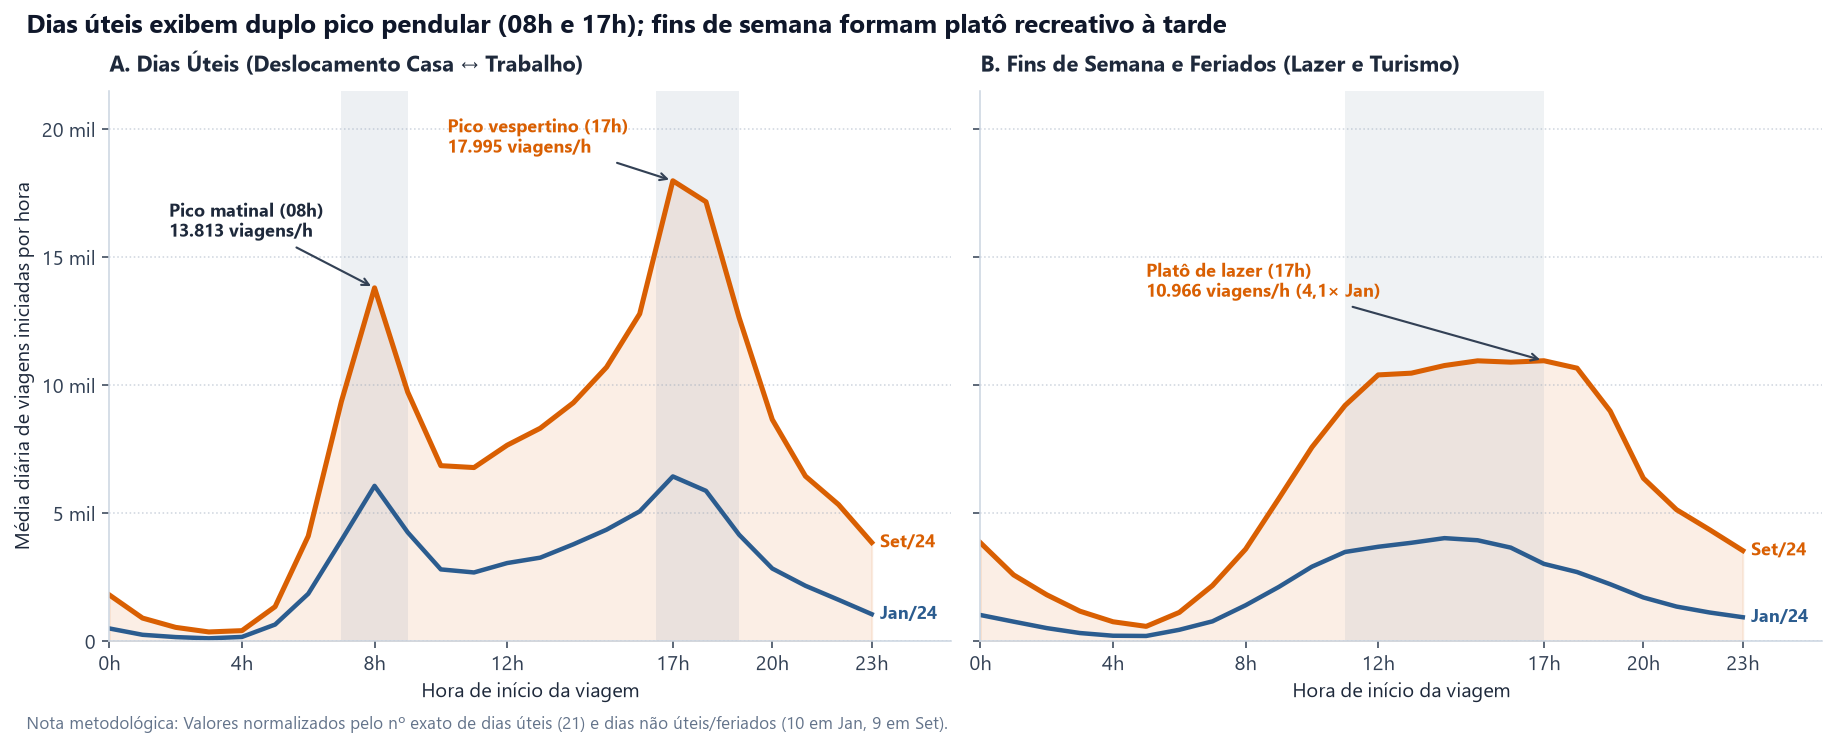

In [4]:
def calcular_curva_horaria_media(df_mes: pd.DataFrame) -> pd.DataFrame:
    dias_por_regime = df_mes.groupby('regime_dia')['data'].nunique()
    contagem_hora = df_mes.groupby(['regime_dia', 'hora']).size().rename('viagens_totais').reset_index()
    contagem_hora['n_dias'] = contagem_hora['regime_dia'].map(dias_por_regime)
    contagem_hora['media_diaria'] = contagem_hora['viagens_totais'] / contagem_hora['n_dias']
    return contagem_hora

curva_jan = calcular_curva_horaria_media(df_jan)
curva_set = calcular_curva_horaria_media(df_set)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0), sharey=True, constrained_layout=True)

fig.suptitle(
    'Dias úteis exibem duplo pico pendular (08h e 17h); fins de semana formam platô recreativo à tarde',
    fontsize=13.5, fontweight='bold', color='#0F172A', x=0.01, ha='left'
)

regimes = [
    ('Dia Útil', 'A. Dias Úteis (Deslocamento Casa ↔ Trabalho)'),
    ('Fim de Semana / Feriado', 'B. Fins de Semana e Feriados (Lazer e Turismo)')
]

for ax, (reg, subtitulo) in zip(axes, regimes):
    s_jan = curva_jan[curva_jan['regime_dia'] == reg].set_index('hora')['media_diaria'].reindex(range(24), fill_value=0)
    s_set = curva_set[curva_set['regime_dia'] == reg].set_index('hora')['media_diaria'].reindex(range(24), fill_value=0)

    ax.plot(s_set.index, s_set.values, color=COR_SET, lw=2.6)
    ax.fill_between(s_set.index, s_set.values, color=COR_SET, alpha=0.10)
    ax.plot(s_jan.index, s_jan.values, color=COR_JAN, lw=2.3)

    if reg == 'Dia Útil':
        ax.axvspan(7, 9, color='#94A3B8', alpha=0.16, ec='none')
        ax.axvspan(16.5, 19, color='#94A3B8', alpha=0.16, ec='none')
        pico_m = s_set.loc[8]
        pico_t = s_set.loc[17]
        ax.annotate(
            f"Pico matinal (08h)\n{fmt_int(pico_m)} viagens/h",
            xy=(8, pico_m), xytext=(1.8, pico_m + 2_000),
            arrowprops=dict(arrowstyle='->', color='#334155', lw=1.1),
            fontsize=9, fontweight='bold', color='#1E293B'
        )
        ax.annotate(
            f"Pico vespertino (17h)\n{fmt_int(pico_t)} viagens/h",
            xy=(17, pico_t), xytext=(10.2, pico_t + 1_100),
            arrowprops=dict(arrowstyle='->', color='#334155', lw=1.1),
            fontsize=9, fontweight='bold', color=COR_SET
        )
    else:
        ax.axvspan(11, 17, color='#94A3B8', alpha=0.14, ec='none')
        hora_max_fds = int(s_set.idxmax())
        val_max_fds = s_set.max()
        ax.annotate(
            f"Platô de lazer ({hora_max_fds}h)\n{fmt_int(val_max_fds)} viagens/h (4,1× Jan)",
            xy=(hora_max_fds, val_max_fds), xytext=(5.0, val_max_fds + 2_500),
            arrowprops=dict(arrowstyle='->', color='#334155', lw=1.1),
            fontsize=9, fontweight='bold', color=COR_SET
        )

    # Rotulagem direta na extremidade direita das curvas (elimina legenda isolada)
    ax.text(23.25, s_set.iloc[-1], 'Set/24', color=COR_SET, fontweight='bold', va='center', fontsize=9.5)
    ax.text(23.25, s_jan.iloc[-1], 'Jan/24', color=COR_JAN, fontweight='bold', va='center', fontsize=9.5)

    ax.set_title(subtitulo, loc='left', fontsize=11.2, pad=10, color='#1E293B')
    ax.set_xlim(0, 25.4)
    ax.set_xticks([0, 4, 8, 12, 17, 20, 23])
    ax.set_xticklabels(['0h', '4h', '8h', '12h', '17h', '20h', '23h'])
    ax.set_xlabel('Hora de início da viagem')
    ax.grid(axis='y', ls=':', alpha=0.45, color='#94A3B8')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].set_ylim(0, 21_500)
axes[0].set_yticks([0, 5_000, 10_000, 15_000, 20_000])
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(round(v/1000))} mil" if v >= 1000 else '0'))
axes[0].set_ylabel('Média diária de viagens iniciadas por hora')

fig.text(
    0.01, -0.03,
    'Nota metodológica: Valores normalizados pelo nº exato de dias úteis (21) e dias não úteis/feriados (10 em Jan, 9 em Set).',
    fontsize=8.5, color='#64748B'
)

plt.savefig(DIR_PLOTS / 'rv3_ritmo_circadiano_demanda.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 5. RV 4 — Distribuição e Acumulada (ECDF) da Duração das Viagens
**Refatoração Estatística (`Aula 11 — Distribuições` e `Caderno 06`):**
- Substituímos o histograma único com bordas pretas pesadas por **curvas KDE suavizadas e estritamente truncadas no domínio físico `[1, 45]` min** (`cut=0, clip=(1, 45)` — zero vazamento para durações negativas/impossíveis), combinadas com uma **ECDF (Função de Distribuição Acumulada Empírica)** imune à escolha arbitrária de *bins*.

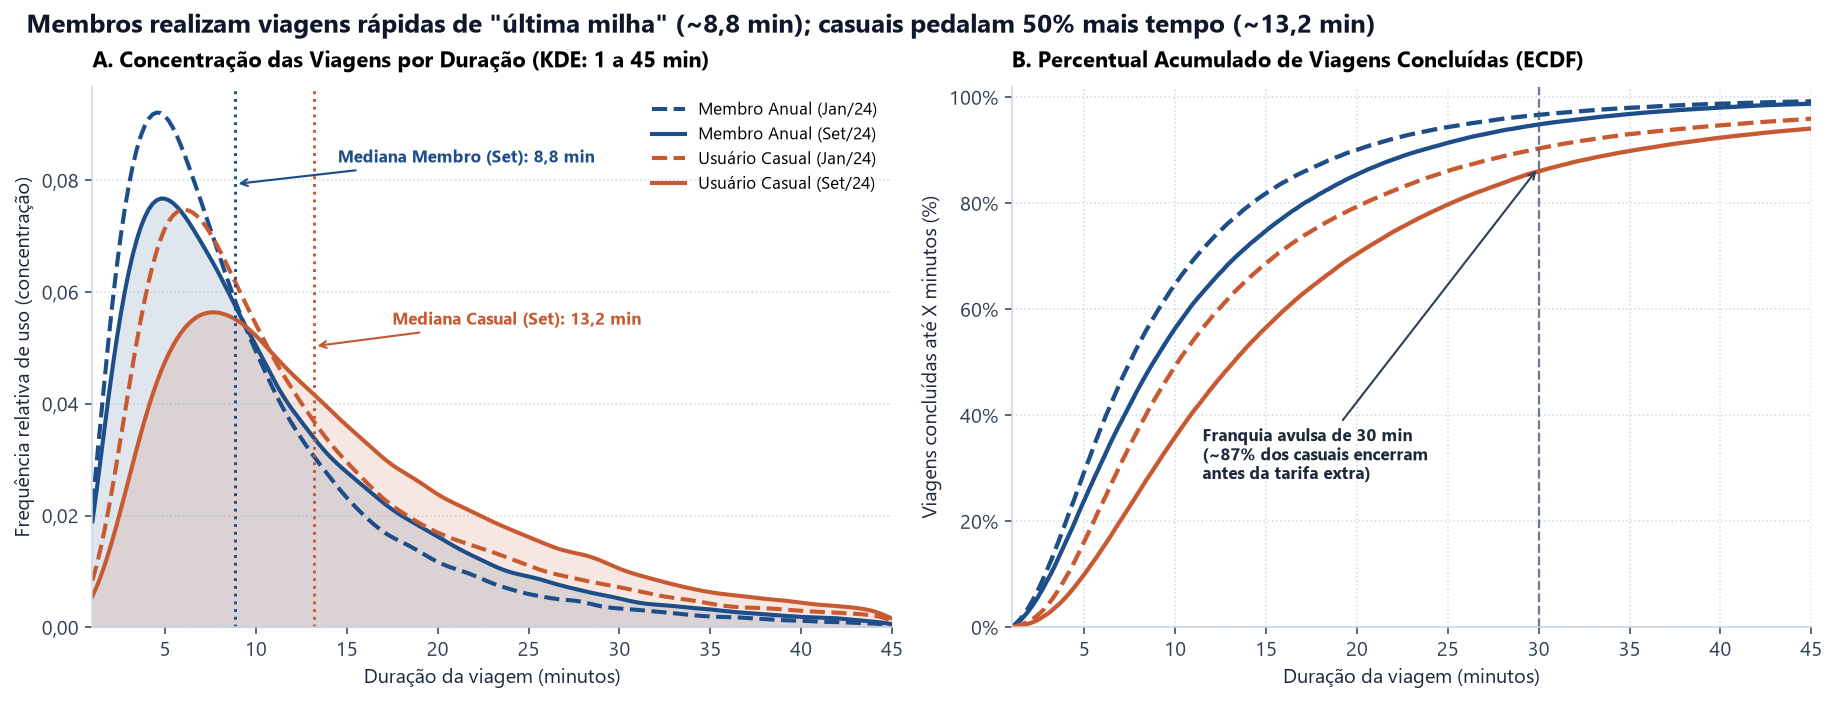

In [5]:
coortes_dist = [
    ('Membro Anual (Jan/24)', df_jan[df_jan['perfil'] == 'Membro Anual']['duracao_min'], COR_MEMBRO, '--'),
    ('Membro Anual (Set/24)', df_set[df_set['perfil'] == 'Membro Anual']['duracao_min'], COR_MEMBRO, '-'),
    ('Usuário Casual (Jan/24)', df_jan[df_jan['perfil'] == 'Usuário Casual']['duracao_min'], COR_CASUAL, '--'),
    ('Usuário Casual (Set/24)', df_set[df_set['perfil'] == 'Usuário Casual']['duracao_min'], COR_CASUAL, '-'),
]

med_membro_set = df_set[df_set['perfil'] == 'Membro Anual']['duracao_min'].median()
med_casual_set = df_set[df_set['perfil'] == 'Usuário Casual']['duracao_min'].median()

fig, (ax_kde, ax_ecdf) = plt.subplots(1, 2, figsize=(13.0, 4.9), constrained_layout=True)

fig.suptitle(
    'Membros realizam viagens rápidas de "última milha" (~8,8 min); casuais pedalam 50% mais tempo (~13,2 min)',
    fontsize=13.2, fontweight='bold', color='#0F172A', x=0.01, ha='left'
)

for rotulo, serie_completa, cor, estilo in coortes_dist:
    amostra = serie_completa.sample(n=min(120_000, len(serie_completa)), random_state=42)
    amostra_45 = amostra[amostra <= 45.0]

    # Painel A: KDE estritamente truncada em [1, 45] min (sem vazamento < 1 min)
    if estilo == '-':
        sns.kdeplot(x=amostra_45, ax=ax_kde, color=cor, lw=0, cut=0, clip=(1.0, 45.0), fill=True, alpha=0.14)
    sns.kdeplot(
        x=amostra_45, ax=ax_kde, color=cor, linestyle=estilo, lw=2.1,
        cut=0, clip=(1.0, 45.0), fill=False, label=rotulo
    )

    # Painel B: ECDF exata no intervalo 1 a 45 min
    vals_ord = np.sort(amostra.to_numpy())
    probs = np.arange(1, len(vals_ord) + 1) / len(vals_ord) * 100.0
    mascara_x = vals_ord <= 45.0
    ax_ecdf.plot(vals_ord[mascara_x], probs[mascara_x], color=cor, linestyle=estilo, lw=2.2, label=rotulo)

# Linhas de mediana de Setembro no KDE posicionadas com apontamento limpo
ax_kde.axvline(med_membro_set, color=COR_MEMBRO, ls=':', lw=1.5)
ax_kde.axvline(med_casual_set, color=COR_CASUAL, ls=':', lw=1.5)
y_top_kde = ax_kde.get_ylim()[1]
ax_kde.annotate(
    f"Mediana Membro (Set): {med_membro_set:.1f} min".replace('.', ','),
    xy=(med_membro_set, y_top_kde * 0.82), xytext=(14.5, y_top_kde * 0.86),
    arrowprops=dict(arrowstyle='->', color=COR_MEMBRO, lw=1.1),
    fontsize=8.6, fontweight='bold', color=COR_MEMBRO
)
ax_kde.annotate(
    f"Mediana Casual (Set): {med_casual_set:.1f} min".replace('.', ','),
    xy=(med_casual_set, y_top_kde * 0.52), xytext=(17.5, y_top_kde * 0.56),
    arrowprops=dict(arrowstyle='->', color=COR_CASUAL, lw=1.1),
    fontsize=8.6, fontweight='bold', color=COR_CASUAL
)

ax_kde.set_title('A. Concentração das Viagens por Duração (KDE: 1 a 45 min)', loc='left', fontsize=11.2, pad=10)
ax_kde.set_xlim(1, 45)
ax_kde.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:.2f}".replace('.', ',')))
ax_kde.set_xlabel('Duração da viagem (minutos)')
ax_kde.set_ylabel('Frequência relativa de uso (concentração)')
ax_kde.grid(axis='y', ls=':', alpha=0.4, color='#94A3B8')
ax_kde.spines['top'].set_visible(False)
ax_kde.spines['right'].set_visible(False)
ax_kde.legend(frameon=False, loc='upper right', fontsize=8.5)

# Marco operacional na ECDF sem sobrepor a linha vertical de 30 min
ax_ecdf.axvline(30, color='#475569', ls='--', lw=1.2, alpha=0.75)
ax_ecdf.annotate(
    'Franquia avulsa de 30 min\n(~87% dos casuais encerram\nantes da tarifa extra)',
    xy=(30, 86.8), xytext=(11.5, 28),
    arrowprops=dict(arrowstyle='->', color='#334155', lw=1.1),
    fontsize=8.6, fontweight='bold', color='#1E293B'
)

ax_ecdf.set_title('B. Percentual Acumulado de Viagens Concluídas (ECDF)', loc='left', fontsize=11.2, pad=10)
ax_ecdf.set_xlim(1, 45)
ax_ecdf.set_ylim(0, 102)
ax_ecdf.yaxis.set_major_formatter(ticker.PercentFormatter())
ax_ecdf.set_xlabel('Duração da viagem (minutos)')
ax_ecdf.set_ylabel('Viagens concluídas até X minutos (%)')
ax_ecdf.grid(axis='both', ls=':', alpha=0.4, color='#94A3B8')
ax_ecdf.spines['top'].set_visible(False)
ax_ecdf.spines['right'].set_visible(False)

plt.savefig(DIR_PLOTS / 'rv4_distribuicao_duracao.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 6. RV 5 — Assimetria Espacial Pendular: Manhã (07h–09h) vs. Tarde (17h–19h)
**Boas Práticas Geoespaciais (`Aula 15 — Dados Geoespaciais`):**
- Complementa as animações de 60 FPS com uma **figura estática em pequenos múltiplos cartográficos (`EPSG:3857` Web Mercator)** sobre fundo neutro desaturado (`Esri.WorldGrayCanvas`).
- Aplica **discretização em 6 faixas simétricas (`BoundaryNorm`)** na escala divergente `RdBu` para leitura exata do saldo médio diário por estação nos dias úteis de Setembro/2024, evidenciando a inversão logística entre bairros residenciais e o centro financeiro/corporativo de Manhattan.

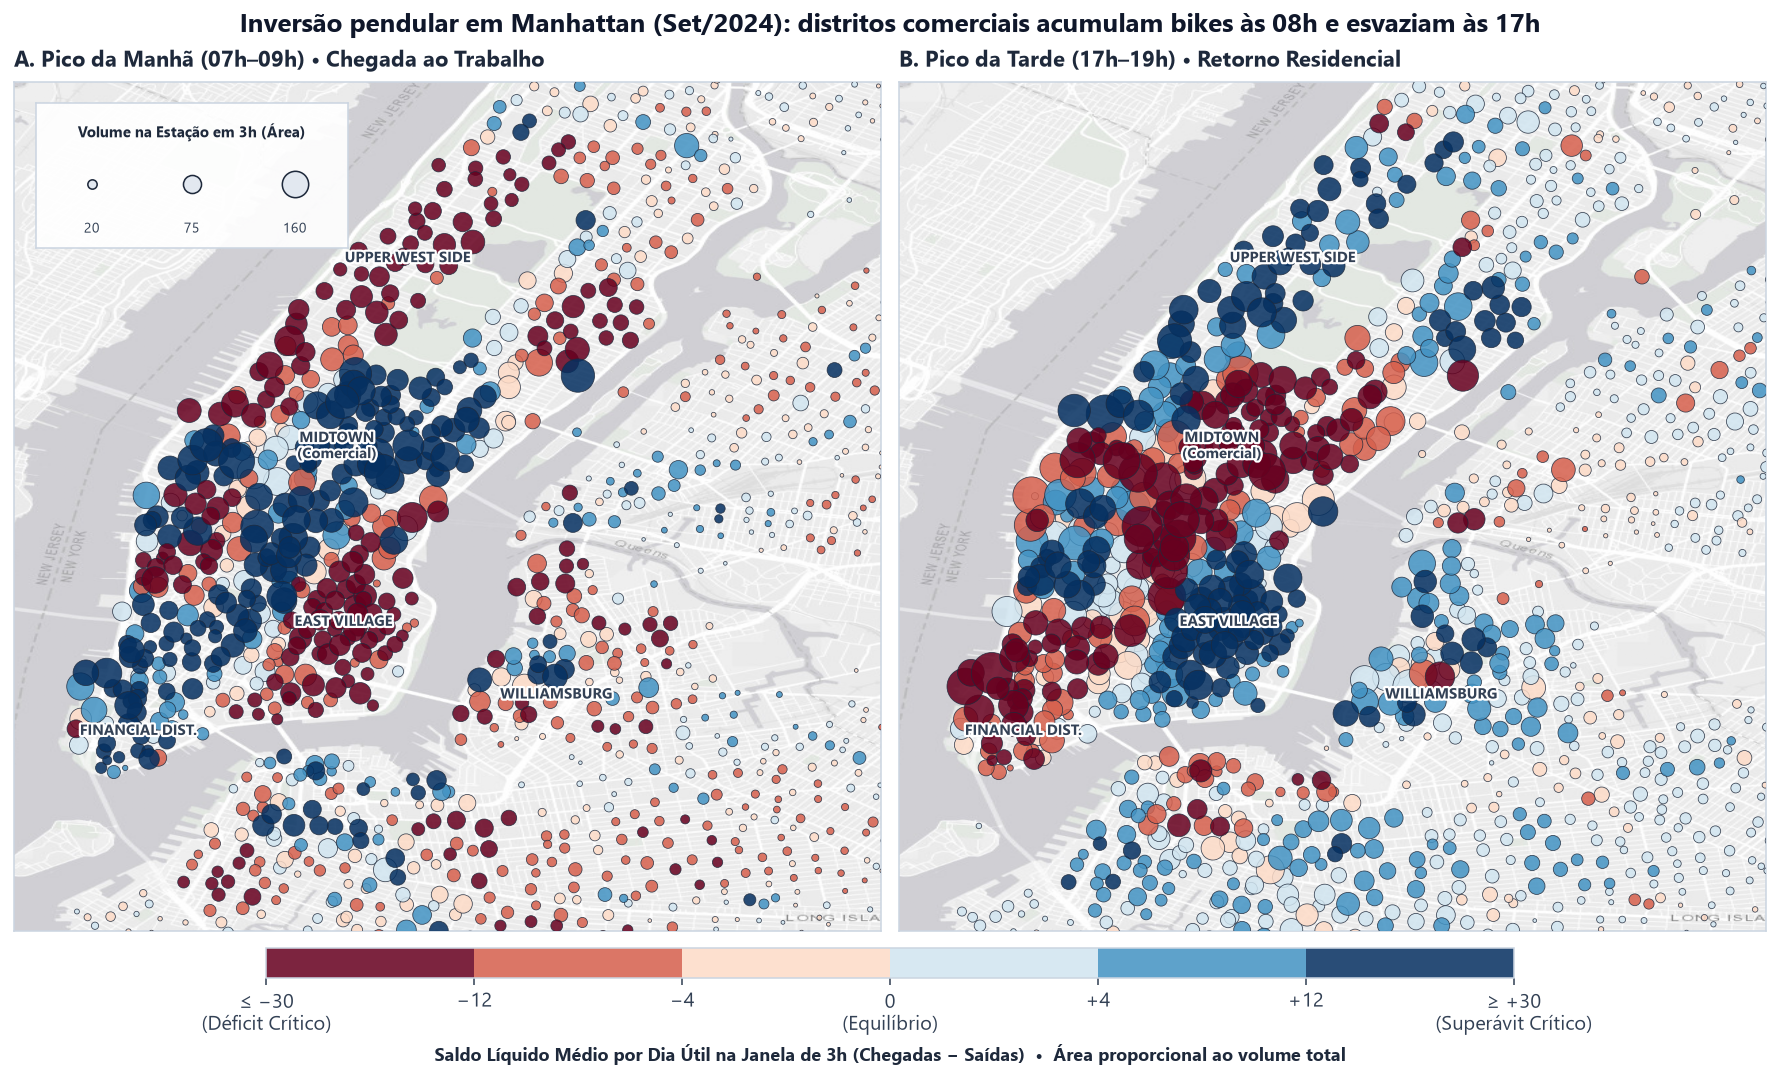

In [6]:
df_set_util = df_set[df_set['regime_dia'] == 'Dia Útil'].copy()
n_dias_uteis = df_set_util['data'].nunique()

cp = df_set_util[['start_station_name', 'start_lat', 'start_lng']].rename(
    columns={'start_station_name': 'estacao', 'start_lat': 'lat', 'start_lng': 'lng'}
)
cc = df_set_util[['end_station_name', 'end_lat', 'end_lng']].rename(
    columns={'end_station_name': 'estacao', 'end_lat': 'lat', 'end_lng': 'lng'}
)
coords_est = pd.concat([cp, cc]).groupby('estacao')[['lat', 'lng']].median().dropna()
gdf_est = gpd.GeoDataFrame(
    coords_est, geometry=gpd.points_from_xy(coords_est['lng'], coords_est['lat']), crs='EPSG:4326'
).to_crs(epsg=3857)
coords_est['x'] = gdf_est.geometry.x
coords_est['y'] = gdf_est.geometry.y

def saldo_janela_horaria(df_u: pd.DataFrame, h_ini: int, h_fim: int) -> pd.DataFrame:
    sub_s = df_u[df_u['started_at'].dt.hour.between(h_ini, h_fim)]
    sub_e = df_u[df_u['ended_at'].dt.hour.between(h_ini, h_fim)]
    s_cnt = sub_s.groupby('start_station_name').size() / n_dias_uteis
    e_cnt = sub_e.groupby('end_station_name').size() / n_dias_uteis
    res = pd.DataFrame({'saidas': s_cnt, 'entradas': e_cnt}).fillna(0.0)
    res['trafego_medio'] = res['saidas'] + res['entradas']
    res['saldo_medio'] = res['entradas'] - res['saidas']
    return res.join(coords_est, how='inner')

est_manha = saldo_janela_horaria(df_set_util, 7, 9)   # 07:00 às 09:59
est_tarde = saldo_janela_horaria(df_set_util, 17, 19) # 17:00 às 19:59

gdf_box = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy([-74.025, -73.915], [40.675, 40.815]), crs='EPSG:4326'
).to_crs(epsg=3857)
xmin_m, xmax_m = gdf_box.geometry.x.min(), gdf_box.geometry.x.max()
ymin_m, ymax_m = gdf_box.geometry.y.min(), gdf_box.geometry.y.max()

# Escala divergente discretizada em 6 classes (Aula 15: facilita leitura quantitativa exata)
limites_bins = [-30, -12, -4, 0, 4, 12, 30]
cmap_disc = plt.get_cmap('RdBu', 6)
norm_disc = mcolors.BoundaryNorm(limites_bins, cmap_disc.N, clip=True)

fig, axes_m = plt.subplots(1, 2, figsize=(12.6, 7.6), constrained_layout=True)
fig.suptitle(
    'Inversão pendular em Manhattan (Set/2024): distritos comerciais acumulam bikes às 08h e esvaziam às 17h',
    fontsize=13.2, fontweight='bold', color='#0F172A'
)

paineis_mapa = [
    (axes_m[0], est_manha, 'A. Pico da Manhã (07h–09h) • Chegada ao Trabalho'),
    (axes_m[1], est_tarde, 'B. Pico da Tarde (17h–19h) • Retorno Residencial'),
]

for ax_m, dados_m, titulo_m in paineis_mapa:
    vis = dados_m[dados_m['trafego_medio'] >= 3.0].sort_values(by='saldo_medio', key=lambda s: s.abs())
    ax_m.set_xlim(xmin_m, xmax_m)
    ax_m.set_ylim(ymin_m, ymax_m)
    ax_m.set_xticks([])
    ax_m.set_yticks([])
    cx.add_basemap(ax_m, source=cx.providers.Esri.WorldGrayCanvas, attribution=False)

    sc_m = ax_m.scatter(
        vis['x'], vis['y'],
        s=vis['trafego_medio'] * 1.15,
        c=vis['saldo_medio'],
        cmap=cmap_disc, norm=norm_disc,
        alpha=0.86, edgecolors='#1E293B', linewidths=0.4, zorder=5
    )
    ax_m.set_title(titulo_m, loc='left', fontsize=11.3, pad=8, color='#1E293B')

    for nome_loc, ln, lt in [
        ('MIDTOWN\n(Comercial)', -73.984, 40.755),
        ('UPPER WEST SIDE', -73.975, 40.786),
        ('EAST VILLAGE', -73.983, 40.726),
        ('FINANCIAL DIST.', -74.009, 40.708),
        ('WILLIAMSBURG', -73.956, 40.714),
    ]:
        pt_loc = gpd.GeoDataFrame(geometry=gpd.points_from_xy([ln], [lt]), crs='EPSG:4326').to_crs(epsg=3857)
        ax_m.text(
            pt_loc.geometry.x.iloc[0], pt_loc.geometry.y.iloc[0], nome_loc,
            fontsize=7.6, fontweight='bold', color='#334155', ha='center', va='center',
            path_effects=[pe.withStroke(linewidth=2.3, foreground='white')], zorder=7
        )

# Legenda quantitativa de área no canto superior esquerdo livre (Nova Jersey)
ax_leg_b = axes_m[0].inset_axes([0.025, 0.805, 0.36, 0.17], zorder=8)
ax_leg_b.set_facecolor((1, 1, 1, 0.92))
for sp in ax_leg_b.spines.values():
    sp.set_edgecolor('#CBD5E1')
    sp.set_linewidth(0.8)
ax_leg_b.set_xticks([])
ax_leg_b.set_yticks([])
ax_leg_b.set_xlim(0, 1)
ax_leg_b.set_ylim(0, 1)
ax_leg_b.text(0.5, 0.80, 'Volume na Estação em 3h (Área)', fontsize=7.6, fontweight='bold', color='#1E293B', ha='center', va='center')
for xv, val_b in [(0.18, 20), (0.50, 75), (0.83, 160)]:
    ax_leg_b.scatter([xv], [0.44], s=val_b * 1.15, facecolor='#E2E8F0', edgecolor='#1E293B', linewidth=0.8, zorder=9)
    ax_leg_b.text(xv, 0.13, f'{val_b}', fontsize=7.3, color='#334155', ha='center', va='center')

cbar = fig.colorbar(sc_m, ax=axes_m, orientation='horizontal', fraction=0.035, pad=0.02, aspect=42, ticks=limites_bins)
cbar.set_label('Saldo Líquido Médio por Dia Útil na Janela de 3h (Chegadas − Saídas)  •  Área proporcional ao volume total', fontweight='bold', fontsize=9.5)
cbar.ax.set_xticklabels(['≤ −30\n(Déficit Crítico)', '−12', '−4', '0\n(Equilíbrio)', '+4', '+12', '≥ +30\n(Superávit Crítico)'])

plt.savefig(DIR_PLOTS / 'rv5_assimetria_espacial_pendular.png', dpi=300, bbox_inches='tight')
plt.show()